<a href="https://colab.research.google.com/github/jazztingacho21-wq/agents-in-sdlc/blob/main/Hypertension_XGBoost_Research_Debugged.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# check lng kag scrool each naka label na

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from google.colab import files
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay
)
from xgboost import XGBClassifier

RANDOM_STATE = 42


#research CSV

In [ ]:
uploaded = files.upload()
csv_name = next(iter(uploaded))
print("Uploaded file:", csv_name)

df = pd.read_csv(csv_name)
print("Dataset shape:", df.shape)
display(df.head())


Saving nhanes_2021_2023_2000_records.csv to nhanes_2021_2023_2000_records (1).csv
Uploaded file: nhanes_2021_2023_2000_records (1).csv
Dataset shape: (2000, 13)


,SEQN,age,sex,weight_kg,height_cm,bmi,waist_cm,alcohol_drinks_per_day,sodium_mg,sleep_hours,physical_activity_min_wk,smoking_status,hypertension
0,130378,25,1,101.6,183.4,30.2,99.5,3.4,3856,5.0,0,1,0
1,130379,67,1,114.8,169.8,39.8,132.8,0.0,3509,4.5,0,0,1
2,130380,59,1,63.2,155.0,26.3,95.8,1.0,3508,5.5,190,0,1
3,130381,46,1,65.0,162.2,24.7,79.6,1.1,4429,4.5,435,2,0
4,130382,46,2,58.1,150.4,25.7,81.8,0.0,3673,7.5,0,0,0


#Check column names and data quality

In [ ]:
# Normalize column labels to lowercase and underscores
df.columns = (
    df.columns.astype(str)
      .str.strip()
      .str.lower()
      .str.replace(r"[^a-z0-9]+", "_", regex=True)
      .str.strip("_")
)

print("Columns:")
print(df.columns.tolist())

print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))

print("\\nData types:")
display(df.dtypes.to_frame("dtype"))


Columns:
['seqn', 'age', 'sex', 'weight_kg', 'height_cm', 'bmi', 'waist_cm', 'alcohol_drinks_per_day', 'sodium_mg', 'sleep_hours', 'physical_activity_min_wk', 'smoking_status', 'hypertension']
\nMissing values:


,missing_count
seqn,0
age,0
sex,0
weight_kg,0
height_cm,0
bmi,0
waist_cm,0
alcohol_drinks_per_day,0
sodium_mg,0
sleep_hours,0


\nData types:


,dtype
seqn,int64
age,int64
sex,int64
weight_kg,float64
height_cm,float64
bmi,float64
waist_cm,float64
alcohol_drinks_per_day,float64
sodium_mg,int64
sleep_hours,float64


In [ ]:

print("Dataset columns:")
print(df.columns.tolist())


Dataset columns:
['seqn', 'age', 'sex', 'weight_kg', 'height_cm', 'bmi', 'waist_cm', 'alcohol_drinks_per_day', 'sodium_mg', 'sleep_hours', 'physical_activity_min_wk', 'smoking_status', 'hypertension']


In [ ]:

print("Hypertension column:")
print(df["hypertension"].value_counts(dropna=False))


Hypertension column:
hypertension
0    1056
1     944
Name: count, dtype: int64


# Validate and prepare target/features

In [ ]:
target = "hypertension"

# These are the input variables specified for the research dataset.
feature_columns = [
    "age",
    "sex",
    "weight_kg",
    "height_cm",
    "bmi",
    "waist_cm",
    "alcohol_drinks_per_day",
    "sodium_mg",
    "sleep_hours",
    "physical_activity_min_wk",
    "smoking_status",
]

required_columns = feature_columns + [target]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(
        "Missing required columns: " + ", ".join(missing_columns) +
        "\\nPlease compare your CSV headers with the expected research columns."
    )

# Convert common target labels to binary. Already-numeric 0/1 values are retained.
target_series = df[target].copy()
if target_series.dtype == "object" or str(target_series.dtype).startswith("string"):
    normalized = target_series.astype("string").str.strip().str.lower()
    target_series = normalized.map({
        "yes": 1, "no": 0,
        "1": 1, "0": 0,
        "true": 1, "false": 0,
        "hypertension": 1, "normal": 0,
    })
else:
    target_series = pd.to_numeric(target_series, errors="coerce")

# Keep rows with known outcome; predictors may contain missing values and will be imputed.
valid = target_series.notna()
df_model = df.loc[valid, required_columns].copy()
y = target_series.loc[valid].astype(int)

# Make sure the target is binary
if not set(y.unique()).issubset({0, 1}):
    raise ValueError(f"Target must be binary 0/1. Found: {sorted(y.unique())}")

X = df_model[feature_columns].copy()

print("Features:", X.shape)
print("Target:", y.shape)
print("Outcome counts (0=No, 1=Yes):")
display(y.value_counts().sort_index().rename("count").to_frame())

if y.nunique() < 2:
    raise ValueError("The target contains only one class; XGBoost needs both 0 and 1.")


Features: (2000, 11)
Target: (2000,)
Outcome counts (0=No, 1=Yes):


,count
hypertension,
0,1056
1,944


In [ ]:
### Dataset Summary

* **Features**: (2000, 11)
* **Target**: (2000,)
* **Outcome counts (0=No, 1=Yes)**:
  * **0 (No)**: 1056
  * **1 (Yes)**: 944

SyntaxError: invalid syntax (2273234393.py, line 3)

# Split data (80% train / 20% test)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 1600
Testing rows: 400


#
# on training folds

In [ ]:
# Detect numeric and categorical fields from the training data.
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [col for col in X_train.columns if col not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop"
)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['age', 'sex', 'weight_kg', 'height_cm', 'bmi', 'waist_cm', 'alcohol_drinks_per_day', 'sodium_mg', 'sleep_hours', 'physical_activity_min_wk', 'smoking_status']
Categorical features: []


#Train and tune XGBoost

In [ ]:
# Calculate imbalance weight using training data only.
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count if positive_count else 1.0

xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    tree_method="hist",
    n_jobs=1
)

# Compact grid: 8 combinations × 5 folds = 40 fits.
param_grid = {
    "classifier__n_estimators": [150, 250],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.05, 0.1],
}

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", xgb)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", round(grid_search.best_score_, 4))


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 150}
Best cross-validation F1: 0.713


#Evaluate on the held-out test set

In [ ]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
}

display(pd.DataFrame([metrics]).round(4))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No hypertension", "Hypertension"], zero_division=0))

print("\\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))


,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.73,0.7143,0.7143,0.7143,0.7805


\nClassification report:
                 precision    recall  f1-score   support

No hypertension       0.74      0.74      0.74       211
   Hypertension       0.71      0.71      0.71       189

       accuracy                           0.73       400
      macro avg       0.73      0.73      0.73       400
   weighted avg       0.73      0.73      0.73       400

\nConfusion matrix:
[[157  54]
 [ 54 135]]


#Visualize model performance

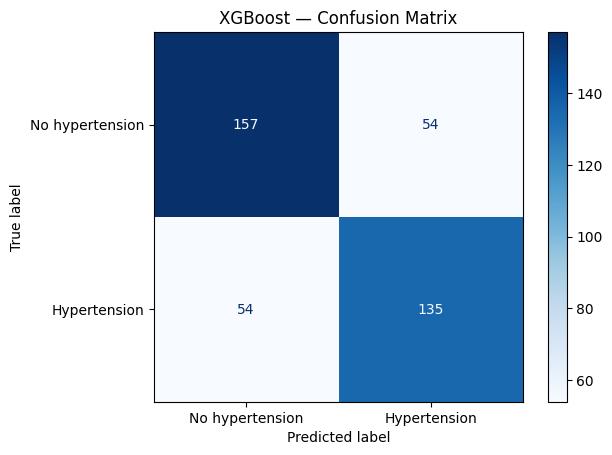

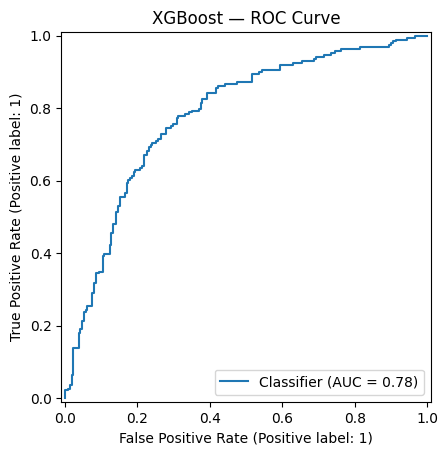

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No hypertension", "Hypertension"],
    cmap="Blues"
)
plt.title("XGBoost — Confusion Matrix")
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("XGBoost — ROC Curve")
plt.show()


#. Feature importance

,feature,importance
0,numeric__age,0.359919
2,numeric__weight_kg,0.089925
4,numeric__bmi,0.085878
9,numeric__physical_activity_min_wk,0.074388
5,numeric__waist_cm,0.068238
1,numeric__sex,0.059779
10,numeric__smoking_status,0.057647
7,numeric__sodium_mg,0.056392
3,numeric__height_cm,0.053697
8,numeric__sleep_hours,0.048745


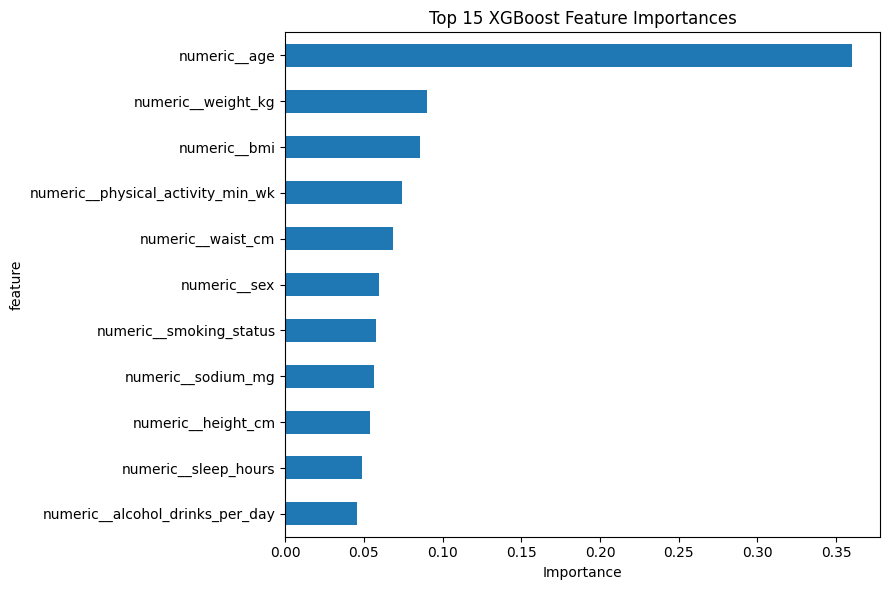

In [ ]:
# Retrieve transformed feature names from the fitted preprocessing step.
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_classifier = best_model.named_steps["classifier"]

try:
    transformed_names = fitted_preprocessor.get_feature_names_out()
    importances = fitted_classifier.feature_importances_
    importance_df = pd.DataFrame({
        "feature": transformed_names,
        "importance": importances
    }).sort_values("importance", ascending=False).head(15)

    display(importance_df)

    importance_df.sort_values("importance").plot(
        x="feature", y="importance", kind="barh", legend=False,
        figsize=(9, 6)
    )
    plt.title("Top 15 XGBoost Feature Importances")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Could not create feature-importance chart:", e)


#Save and download the complete model

In [ ]:
# Save preprocessing + trained XGBoost model together.
model_filename = "hypertension_xgboost_pipeline.pkl"
joblib.dump(best_model, model_filename)

# Save a small metadata file documenting the expected input columns.
metadata = {
    "target": target,
    "features": feature_columns,
    "target_encoding": {"0": "No hypertension", "1": "Hypertension"},
    "random_state": RANDOM_STATE,
    "best_params": grid_search.best_params_,
    "test_metrics": metrics,
}
joblib.dump(metadata, "hypertension_model_metadata.pkl")

print("Saved:", model_filename)
print("Saved: hypertension_model_metadata.pkl")

files.download(model_filename)


Saved: hypertension_xgboost_pipeline.pkl
Saved: hypertension_model_metadata.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Example: predict one new record

In [ ]:
# Replace the example values with a real, correctly measured record.
# Note: categorical features like sex and smoking_status must be numeric codes matching your dataset.
example = pd.DataFrame([{
    "age": 50,
    "sex": 1,                  # Numeric representation (e.g., 1 or 2)
    "weight_kg": 70.0,
    "height_cm": 160.0,
    "bmi": 27.3,
    "waist_cm": 88.0,
    "alcohol_drinks_per_day": 0,
    "sodium_mg": 2000,
    "sleep_hours": 7,
    "physical_activity_min_wk": 150,
    "smoking_status": 1         # Numeric representation matching training data
}])[feature_columns]

probability = best_model.predict_proba(example)[0, 1]
prediction = int(probability >= 0.5)

print("Predicted class:", "Hypertension" if prediction == 1 else "No hypertension")
print("Predicted probability:", round(float(probability), 4))
print("Research prototype only — not a medical diagnosis.")

Predicted class: No hypertension
Predicted probability: 0.4065
Research prototype only — not a medical diagnosis.
